# 1-1 수요 필터 · 1-2 소비 갭 (수정본)

1차 버전 대비 변경점
1. **업종 범위**: 금액_5업종 → **금액_음식소매** (팀 결정: 주 지표 = 음식·소매)
2. **수요 필터**: 방문 하위 25% 제외 → **방문 또는 외국인 카드 결제건수 중 하나라도 하위 25% 초과면 통과 (OR)**
   - 방문(SKT)은 30분 체류 기준이라 전통시장 등 과소 집계 → 결제로 보완
   - AND는 결제 적은 동(=소비 갭 큰 동)을 먼저 걸러내 순환 논리가 되므로 사용 안 함
3. **소비 갭 원인 분해 추가 (셀 10-2)**: 방문당 소비 = 전환(건수/방문) × 객단가(금액/건수) → 동별 주원인 표시

나머지 셀(그래프, 2×2, 최종표)은 원본 그대로이며, 표에 전환·객단가·주원인 열만 추가함.

In [ ]:
# ============================================
# 셀 1. 라이브러리 및 한글 폰트 설정
# ============================================
!pip -q install adjustText
!apt-get -qq -y install fonts-nanum > /dev/null

import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns
from matplotlib.ticker import FuncFormatter
from matplotlib.patches import Patch, Rectangle
from adjustText import adjust_text
from IPython.display import display

fm.fontManager.addfont('/usr/share/fonts/truetype/nanum/NanumGothic.ttf')
sns.set_style('whitegrid')
plt.rcParams['font.family'] = 'NanumGothic'
plt.rcParams['axes.unicode_minus'] = False
pd.options.display.float_format = '{:,.2f}'.format
pd.options.display.max_columns = 100
comma = FuncFormatter(lambda x, _: f'{x:,.0f}')

In [ ]:
# ============================================
# 셀 2. 마스터_A_동.csv 업로드 및 불러오기
# ============================================
from google.colab import files
uploaded = files.upload()          # 마스터_A_동.csv 선택
fname = [k for k in uploaded if '마스터_A' in k][0]
df = pd.read_csv(fname, encoding='utf-8-sig')
df.columns = df.columns.str.replace('\ufeff', '', regex=False).str.strip()
print('불러온 파일:', fname, '| shape =', df.shape)

In [ ]:
# ============================================
# 셀 3. 데이터 구조 및 컬럼 확인
# ============================================
print('1) 행/열 수:', df.shape)
print('\n2) 전체 컬럼명:\n', list(df.columns))
print('\n3) 데이터 타입')
display(df.dtypes.to_frame('dtype'))
print('\n4) 상위 5개 행')
display(df.head())

def find_cols(keys):
    return [c for c in df.columns if any(k in c for k in keys)]

date_cols = find_cols(['연월', '년월', '기준월', '일자', '날짜', 'date', 'month'])
print('\n5) 날짜/연월 관련 컬럼:', date_cols if date_cols else '없음 (A 파일은 읍면동 단위 집계본)')
print('6) 읍면동 식별 컬럼:', find_cols(['행정동', '시', '권역']))
print('7) 방문객 관련 컬럼:', find_cols(['방문']))
print('8) 소비금액 관련 컬럼:', find_cols(['금액']))
print('9) 내/외국인 관련 컬럼:', find_cols(['내국', '외국', '국적', '중국홍콩']),
      '→ 비율 컬럼만 있고, 방문객/소비를 내·외국인으로 나눈 값은 없음')
print('10) 업종별 구분 컬럼:', find_cols(['5업종', '음식소매', '숙박']))

# ---- 분석에 사용할 실제 컬럼 정의 ----
CODE   = '행정동코드'
REGION = '행정동명'
VISIT  = '방문'
SPEND_COL = '금액_음식소매'    # [수정] 5업종 → 음식소매 (팀 결정: 주 지표 = 음식·소매)
CNT_COL   = '건수_음식소매'    # [추가] 전환·객단가 계산과 수요 필터에 사용
for c in [CODE, REGION, VISIT, SPEND_COL, CNT_COL, '시', '권역']:
    assert c in df.columns, f'컬럼 없음: {c}'
print('\n[분석에 사용할 변수]')
print(f' 지역 변수 = {REGION} (코드: {CODE}, 상위: 시/권역)')
print(f' 연월 변수 = {date_cols[0] if date_cols else "없음"}')
print(f' 방문객 변수 = {VISIT}')
print(f' 관광소비금액 변수 = {SPEND_COL}')
print(f' 결제건수 변수 = {CNT_COL}')

print('\n11) 주요 변수 결측치')
display(df[[CODE, REGION, VISIT, SPEND_COL]].isna().sum().to_frame('결측치 수'))
print('12) 중복: 완전중복 행 =', df.duplicated().sum(), '| 행정동코드 중복 =', df[CODE].duplicated().sum(),
      '| 행정동명 중복 =', df[REGION].duplicated().sum())

print('\n13) 이상치 점검 (IQR 1.5배 기준)')
rows = []
for c in [VISIT, SPEND_COL]:
    q1, q3 = df[c].quantile([.25, .75]); iqr = q3 - q1
    out = df[(df[c] > q3 + 1.5*iqr) | (df[c] < q1 - 1.5*iqr)][REGION].tolist()
    rows.append({'변수': c, '최소': df[c].min(), '중앙값': df[c].median(), '최대': df[c].max(),
                 '이상치 수': len(out), '이상치 지역': ', '.join(out)})
display(pd.DataFrame(rows))
print('방문 ≤ 0 인 행 수:', (df[VISIT] <= 0).sum())

In [ ]:
# ============================================
# 셀 4. 데이터 전처리 및 최근 12개월 추출
# ============================================
work = df.copy()
N_MONTHS = None
PERIOD_LABEL = None

if date_cols:
    dc = date_cols[0]
    ym = pd.to_datetime(work[dc].astype(str).str[:6], format='%Y%m', errors='coerce')
    work['_ym'] = ym.dt.to_period('M')
    last = work['_ym'].max()
    first = last - 11
    work = work[(work['_ym'] >= first) & (work['_ym'] <= last)]
    N_MONTHS = work['_ym'].nunique()
    PERIOD_LABEL = f'{first} ~ {last}'
    print(f'분석기간: {PERIOD_LABEL} (포함 월 수 = {N_MONTHS})')
else:
    print('※ 마스터_A_동.csv에는 연월 컬럼이 없어 월 단위 필터링이 불가능합니다.')
    print('  → 파일 전체를 이미 집계된 분석기간으로 간주합니다. (실제 기간은 A 파일만으로 검증 불가)')
    print('  → 월평균 방문객 수는 기간 길이를 알 수 없어 계산하지 않습니다.')

V, S, SPV = '최근12개월_방문객수', '최근12개월_관광소비금액', '방문당소비'
C = '최근12개월_결제건수'   # [추가]
agg = (work.groupby([CODE, REGION, '시', '권역'], as_index=False)
           .agg(**{V: (VISIT, 'sum'), S: (SPEND_COL, 'sum'), C: (CNT_COL, 'sum')}))

print('\n추출 확인: 행 수 =', len(work), '| 읍면동 수 =', agg[REGION].nunique(),
      '| 방문 합계 =', f'{agg[V].sum():,.0f}', '| 소비 합계 =', f'{agg[S].sum():,.0f}')

In [ ]:
# ============================================
# 셀 5. 읍면동별 최근 12개월 방문객 집계
# ============================================
total_visit = agg[V].sum()
agg['방문객비중(%)'] = agg[V] / total_visit * 100
cols5 = [REGION, V, '방문객비중(%)']
if N_MONTHS:
    agg['월평균방문객수'] = agg[V] / N_MONTHS
    cols5.insert(2, '월평균방문객수')

tbl5 = agg.sort_values(V, ascending=False)[cols5].rename(
    columns={REGION: '읍면동', '방문객비중(%)': '방문객비중'}).reset_index(drop=True)
display(tbl5)

In [ ]:
# ============================================
# 셀 6. 수요 필터 [수정: 이중 기준 = 방문 또는 외국인 카드 결제]
# ============================================
# 방문객(SKT)은 30분 이상 체류만 집계해 시장처럼 짧게 들르는 곳을 과소 집계함
# → 외국인 카드 결제 건수로 보완: 둘 중 하나라도 하위가 아니면 수요가 있다고 판단
Q_CUT = 0.25      # 하위 몇 %를 제외할지 (민감도: 0.20 / 0.25 / 0.30)
MODE  = 'OR'      # 'OR' 권장. 'AND'는 카드 결제가 적은 동(=소비 갭 큰 동)을 필터에서 먼저 걸러내 순환 논리가 됨

def demand_filter(q, mode):
    tv, tc = agg[V].quantile(q), agg[C].quantile(q)
    pv, pc = agg[V] > tv, agg[C] > tc
    return ((pv | pc) if mode == 'OR' else (pv & pc)), tv, tc

# 기준 비교표 (민감도)
rows = []
for q in [0.20, 0.25, 0.30]:
    for mode in ['방문만', 'OR', 'AND']:
        passed_ = (agg[V] > agg[V].quantile(q)) if mode == '방문만' else demand_filter(q, mode)[0]
        rows.append({'하위 제외': f'{int(q*100)}%', '방식': mode, '통과 지역 수': int(passed_.sum()),
                     '통과지역 방문객 비중(%)': agg.loc[passed_, V].sum() / agg[V].sum() * 100,
                     '통과지역 결제건수 비중(%)': agg.loc[passed_, C].sum() / agg[C].sum() * 100})
display(pd.DataFrame(rows))

# 최종 적용
passed, THR, THR_C = demand_filter(Q_CUT, MODE)
agg['방문_통과'] = (agg[V] > THR).astype(int)
agg['결제_통과'] = (agg[C] > THR_C).astype(int)
agg['수요필터_통과'] = passed.astype(int)
SEL_RULE = (f'방문 또는 결제건수 하위 {int(Q_CUT*100)}% 제외' if MODE == 'OR'
            else f'방문·결제건수 모두 하위 {int(Q_CUT*100)}% 초과')
v = agg[V]; skew = v.skew()     # 아래 그래프 셀에서 사용

print(f'\n[최종 선택] {SEL_RULE}')
print(f' - 방문 기준값 {THR:,.0f} / 결제건수 기준값 {THR_C:,.0f}')
print(f' - 통과 {int(passed.sum())}개 / 탈락 {int((~passed).sum())}개')
print(' - 결제 기준으로 복귀한 지역 (방문은 하위지만 결제는 충분):', agg.loc[(agg['방문_통과'] == 0) & passed, REGION].tolist())
print(' - 최종 탈락 지역 (방문·결제 모두 하위):', agg.loc[~passed, REGION].tolist())
print('선택 이유: 방문객 데이터는 30분 이상 체류 기준이라 전통시장처럼 짧게 들르는 곳을 과소 집계함. '
      '외국인 카드 결제가 충분한 곳은 실제 수요가 있으므로 함께 인정함. '
      'AND 방식은 결제가 적은 동(=소비 갭이 큰 동)을 1단계에서 제외해 분석 목적과 충돌하므로 사용하지 않음.')


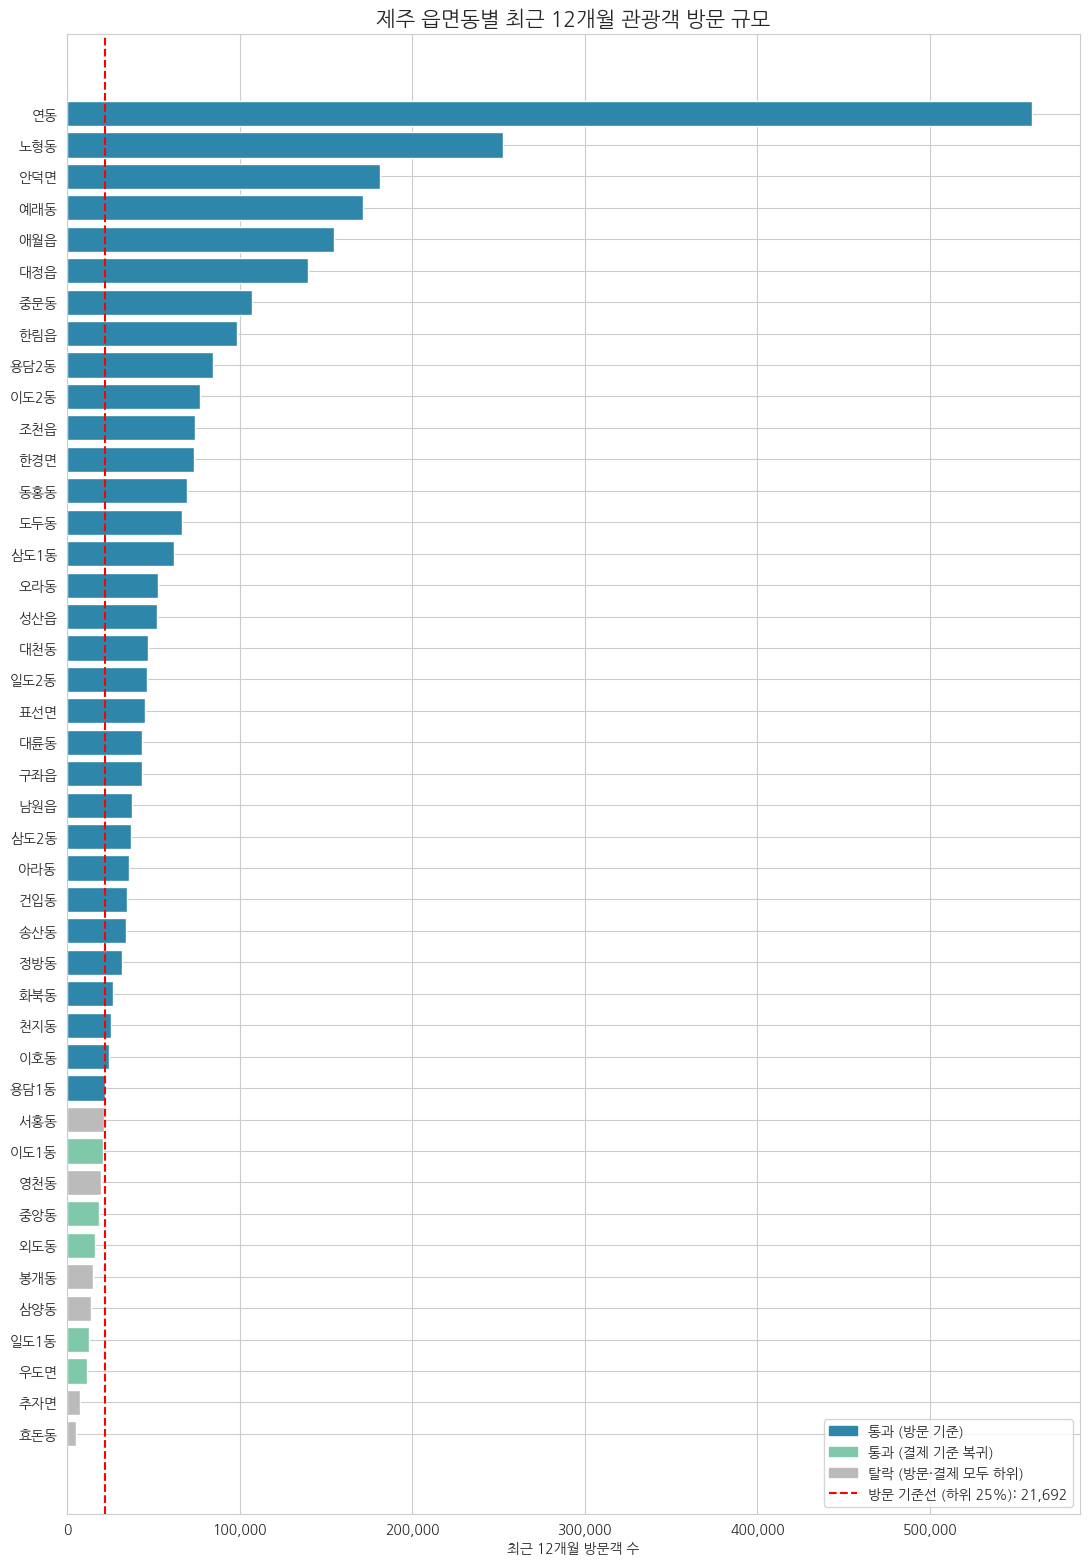

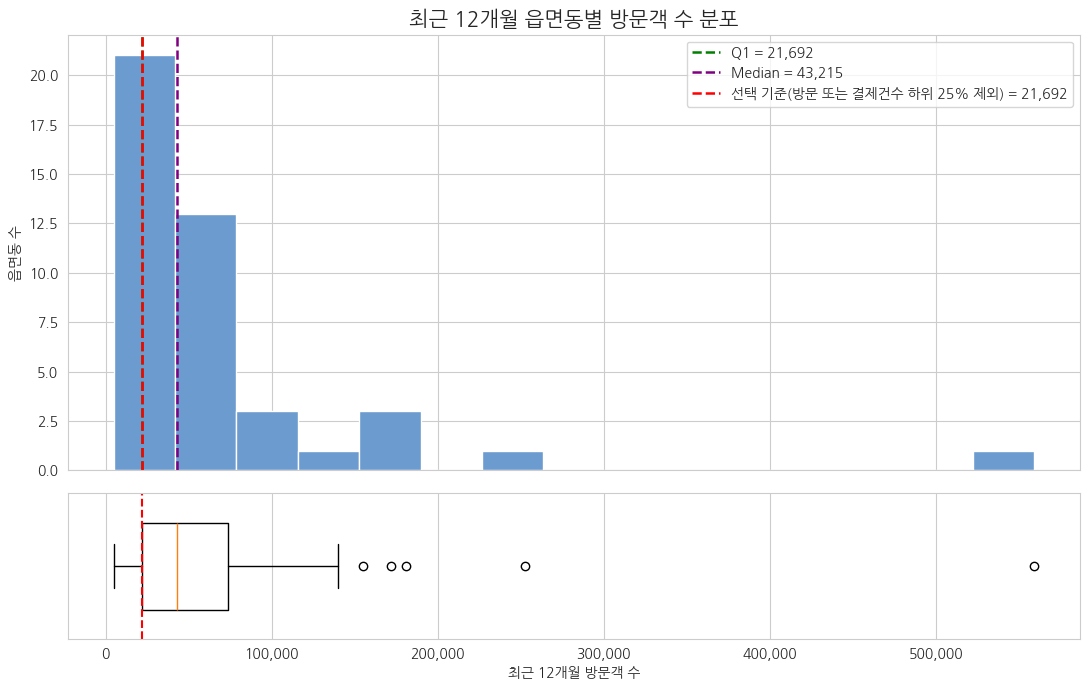

In [ ]:
# ============================================
# 셀 7. 수요 필터 결과표 + 시각화 (그래프 1, 2)
# ============================================
t7 = agg.sort_values(V, ascending=False)[[REGION, V, '방문객비중(%)', '수요필터_통과']] \
        .rename(columns={REGION: '읍면동'}).reset_index(drop=True)
display(t7)

# ---- 그래프 1 ----
d = agg.sort_values(V, ascending=False).reset_index(drop=True)
colors = np.where(d['방문_통과'] == 1, '#2E86AB', np.where(d['수요필터_통과'] == 1, '#7FC8A9', '#BBBBBB'))
fig, ax = plt.subplots(figsize=(11, 0.32*len(d) + 2))
ax.barh(d[REGION], d[V], color=colors)
ax.invert_yaxis()
ax.axvline(THR, color='red', ls='--', lw=1.5)
ax.xaxis.set_major_formatter(comma)
ax.set_xlabel('최근 12개월 방문객 수')
ax.set_title('제주 읍면동별 최근 12개월 관광객 방문 규모', fontsize=15, fontweight='bold')
ax.legend(handles=[Patch(color='#2E86AB', label='통과 (방문 기준)'), Patch(color='#7FC8A9', label='통과 (결제 기준 복귀)'),
                   Patch(color='#BBBBBB', label='탈락 (방문·결제 모두 하위)'),
                   plt.Line2D([0], [0], color='red', ls='--', label=f'방문 기준선 (하위 {int(Q_CUT*100)}%): {THR:,.0f}')],
          loc='lower right')
plt.tight_layout(); plt.show()

n_pass = int(agg['수요필터_통과'].sum())
print(f'해석: {len(agg)}개 읍면동 중 {n_pass}개가 수요 필터를 통과했습니다. '
      f'방문객이 가장 많은 지역은 {d.loc[0, REGION]}({d.loc[0, V]:,.0f})이며, '
      f'통과 지역이 전체 방문객의 {agg.loc[agg["수요필터_통과"]==1, V].sum()/total_visit*100:.1f}%를 차지합니다.')

# ---- 그래프 2 ----
q1, med = v.quantile(.25), v.median()
fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 7), sharex=True, gridspec_kw={'height_ratios': [3, 1]})
a1.hist(v, bins=15, color='#6C9BCF', edgecolor='white')
for val, lab, col in [(q1, f'Q1 = {q1:,.0f}', 'green'), (med, f'Median = {med:,.0f}', 'purple'),
                      (THR, f'선택 기준({SEL_RULE}) = {THR:,.0f}', 'red')]:
    a1.axvline(val, color=col, ls='--', lw=1.8, label=lab)
a1.set_ylabel('읍면동 수'); a1.legend()
a1.set_title('최근 12개월 읍면동별 방문객 수 분포', fontsize=15, fontweight='bold')
a2.boxplot(v, vert=False, widths=0.6)
a2.axvline(THR, color='red', ls='--', lw=1.5)
a2.set_yticks([]); a2.xaxis.set_major_formatter(comma); a2.set_xlabel('최근 12개월 방문객 수')
plt.tight_layout(); plt.show()

print(f'해석: 방문객 수는 중앙값 {med:,.0f}, 최대 {v.max():,.0f}로 소수 지역에 크게 쏠린 분포(왜도 {skew:.2f})입니다. '
      f'Q1({q1:,.0f}) 이하는 방문 규모가 작은 하위 지역군이며, 선택한 기준({THR:,.0f})은 이 분포에서 '
      f'방문 규모가 작은 지역을 분리하는 선으로 작동합니다.')

In [ ]:
# ============================================
# 셀 8. 읍면동별 관광소비금액 집계 및 방문당 소비 계산
# ============================================
agg[SPV] = np.where(agg[V] > 0, agg[S] / agg[V], np.nan)   # division by zero 방지
agg['전환'] = agg[C] / agg[V]       # [추가] 방문 1회당 결제 건수
agg['객단가'] = agg[S] / agg[C]     # [추가] 결제 1건당 금액

print(f'소비금액 컬럼: {SPEND_COL} | 방문당 소비 = {S} / {V}  (금액 단위는 원본 CSV 단위 그대로)')

# 검증: CSV에 이미 있는 방문당소비 컬럼과 비교
ref_map = {'금액_5업종': '방문당소비_5업종', '금액_음식소매': '방문당소비_음식소매'}
rc = ref_map.get(SPEND_COL)
if rc in df.columns:
    chk = agg[[CODE, SPV]].merge(df[[CODE, rc]], on=CODE)
    print(f'[검증] 재계산 방문당소비 vs CSV의 {rc}: 상관계수={chk[SPV].corr(chk[rc]):.4f}, '
          f'중앙값 비율={(chk[SPV]/chk[rc]).median():.4f}')

t8 = agg.sort_values(SPV, ascending=False)[[REGION, V, S, SPV, '전환', '객단가', '수요필터_통과']] \
        .rename(columns={REGION: '읍면동'}).reset_index(drop=True)
print('\n[수요 필터 통과 지역 - 방문당 소비 높은 순]')
display(t8[t8['수요필터_통과'] == 1].reset_index(drop=True))
print('[수요 필터 탈락 지역 - 참고]')
display(t8[t8['수요필터_통과'] == 0].reset_index(drop=True))

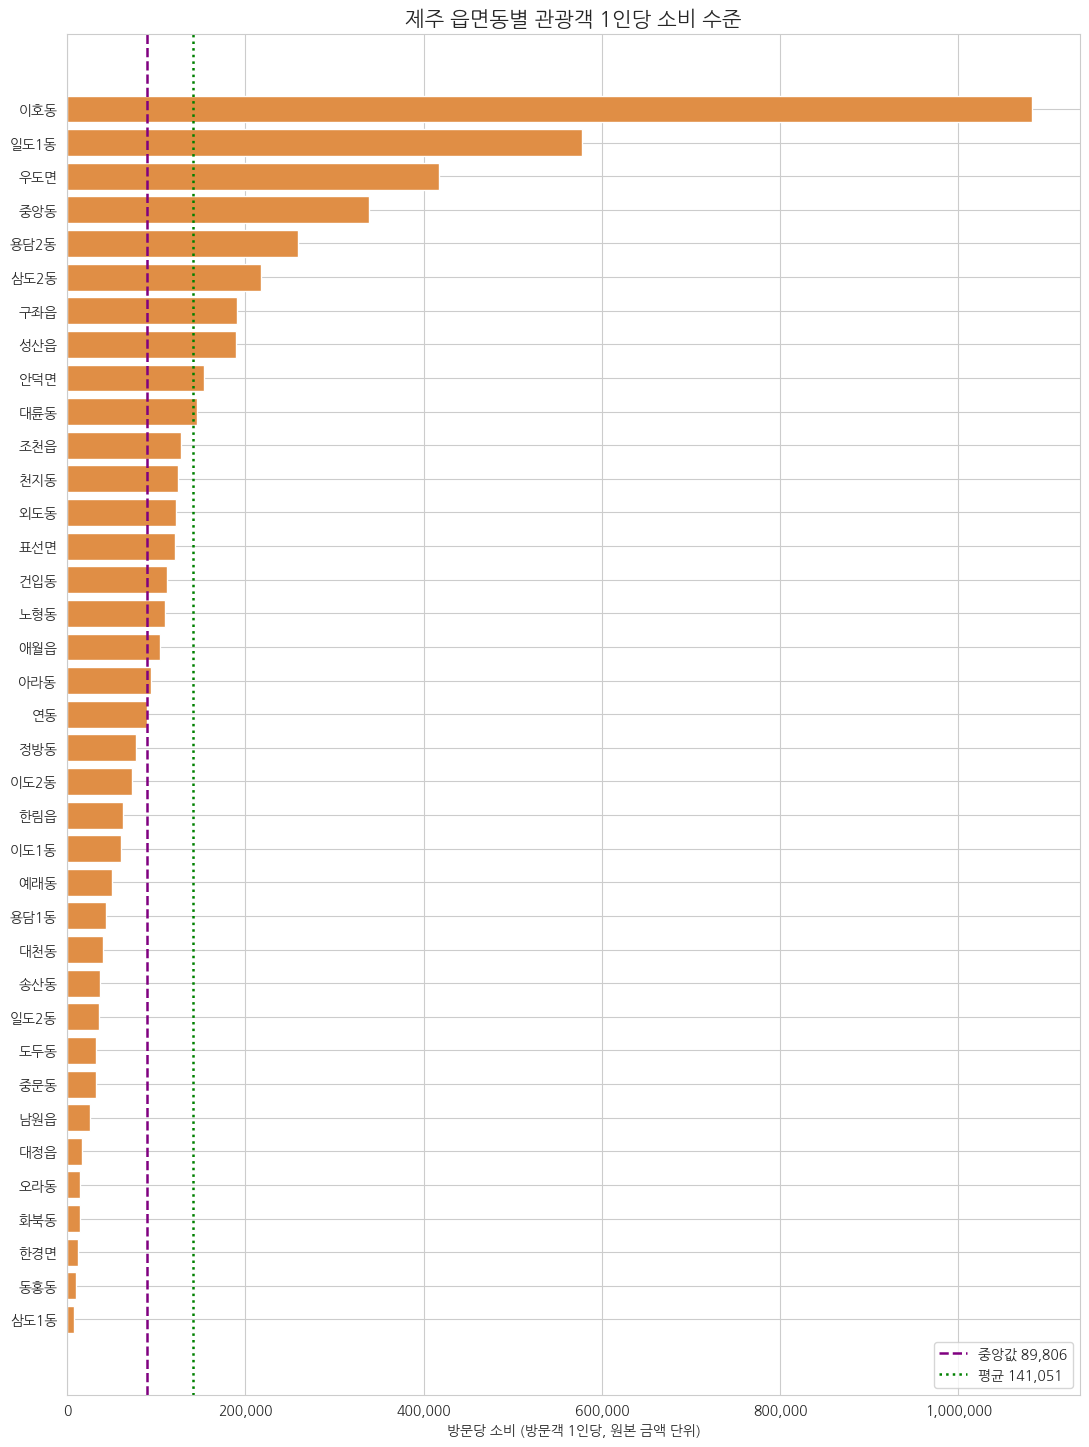

In [ ]:
# ============================================
# 셀 9. 방문당 소비 시각화 (그래프 3)
# ============================================
p = agg[agg['수요필터_통과'] == 1].sort_values(SPV, ascending=False).reset_index(drop=True)
fig, ax = plt.subplots(figsize=(11, 0.34*len(p) + 2))
ax.barh(p[REGION], p[SPV], color='#E08E45')
ax.invert_yaxis()
ax.axvline(p[SPV].median(), color='purple', ls='--', lw=1.8, label=f'중앙값 {p[SPV].median():,.0f}')
ax.axvline(p[SPV].mean(), color='green', ls=':', lw=1.8, label=f'평균 {p[SPV].mean():,.0f}')
ax.xaxis.set_major_formatter(comma)
ax.set_xlabel('방문당 소비 (방문객 1인당, 원본 금액 단위)')
ax.set_title('제주 읍면동별 관광객 1인당 소비 수준', fontsize=15, fontweight='bold')
ax.legend(loc='lower right'); plt.tight_layout(); plt.show()

print(f'해석: 수요 필터 통과 {len(p)}개 지역 중 방문당 소비가 가장 높은 곳은 {p.loc[0, REGION]}({p.loc[0, SPV]:,.0f}), '
      f'가장 낮은 곳은 {p.loc[len(p)-1, REGION]}({p.loc[len(p)-1, SPV]:,.0f})로 '
      f'최고·최저 격차는 {p[SPV].max()/p[SPV].min():.1f}배입니다. 중앙값은 {p[SPV].median():,.0f}, 평균은 {p[SPV].mean():,.0f}입니다.')

In [ ]:
# ============================================
# 셀 10. 소비 갭 계산
# ============================================
FORCE_REF = None      # '평균' 또는 '중앙값'으로 직접 지정 가능
p = agg[agg['수요필터_통과'] == 1]
mean_, med_ = p[SPV].mean(), p[SPV].median()
rel = abs(mean_ - med_) / med_
REF_RULE = FORCE_REF or ('중앙값' if rel > 0.10 else '평균')
REF = med_ if REF_RULE == '중앙값' else mean_

display(pd.DataFrame({'기준 후보': ['평균', '중앙값'], '방문당소비': [mean_, med_]}))
print(f'평균-중앙값 상대차이 = {rel*100:.1f}% | 통과 지역 방문당소비 왜도 = {p[SPV].skew():.2f}')
print(f'[선택] 기준 방문당 소비 = 수요 필터 통과 지역의 {REF_RULE} = {REF:,.0f}')
print('소비갭 = 기준 방문당 소비 - 해당 읍면동 방문당 소비  (양수 = 기준보다 1인당 소비가 낮음)')

agg['소비갭'] = REF - agg[SPV]
agg['소비갭_순위'] = agg.loc[agg['수요필터_통과'] == 1, '소비갭'].rank(ascending=False, method='min')

t10 = agg[agg['수요필터_통과'] == 1].sort_values('소비갭', ascending=False)[
    [REGION, V, SPV, '소비갭', '소비갭_순위']].rename(columns={REGION: '읍면동'}).reset_index(drop=True)
display(t10)

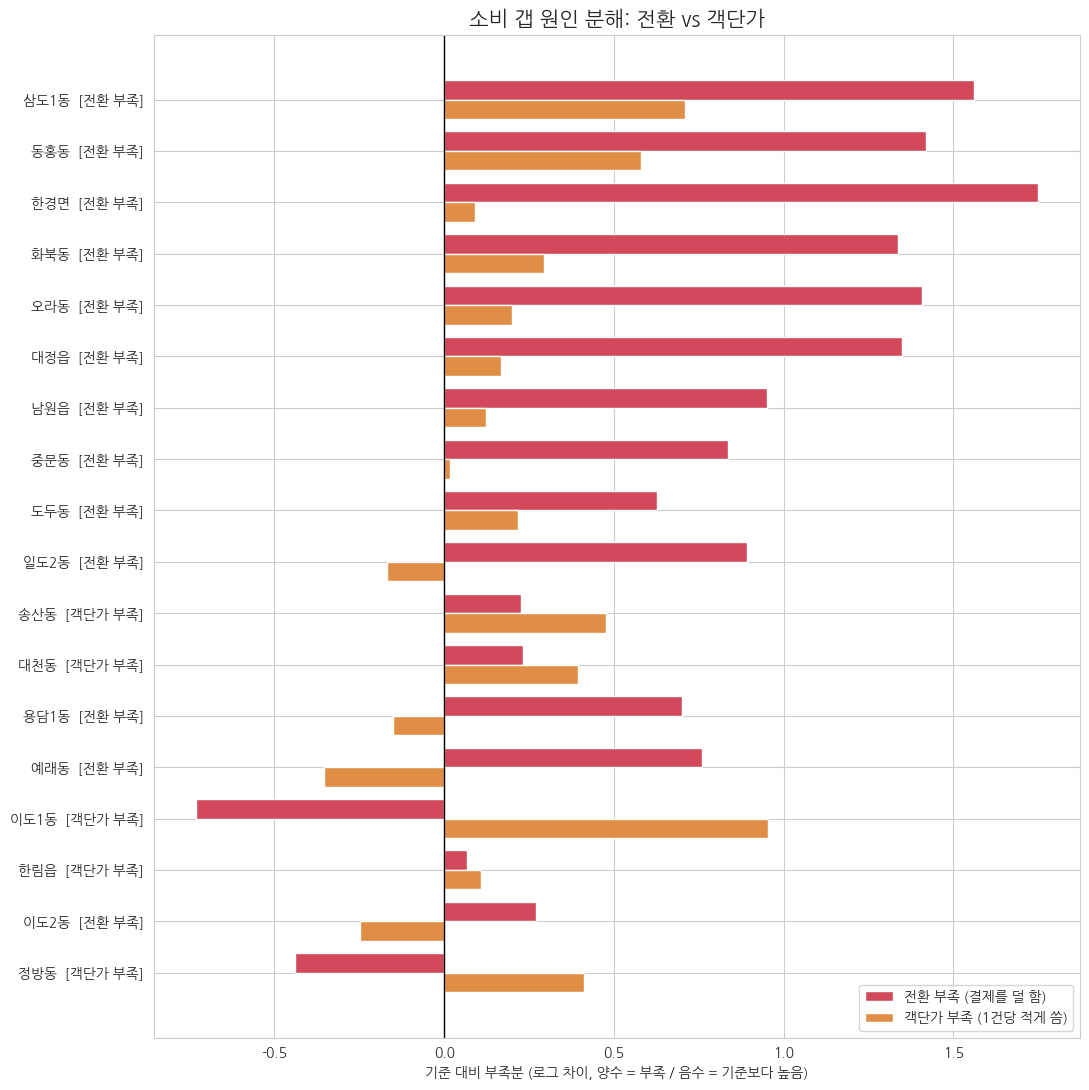

In [ ]:
# ============================================
# 셀 10-2. [추가] 소비 갭 원인 분해: 전환 부족 vs 객단가 부족
# ============================================
# 로그로 바꾸면 덧셈이 되므로, 기준(통과 지역 기하평균) 대비 부족분을 두 요인으로 정확히 나눌 수 있음
# ※ 소비 갭(셀 10)은 중앙값 기준, 원인 분해는 기하평균 기준이라 기준이 다름        ← 추가
#   → 두 기준 사이에 있는 경계 동(예: 정방동)은 주원인 해석에 주의 (참고용)        ← 추가
# 방문당 소비 = 전환(결제건수/방문) × 객단가(금액/결제건수)
# 로그로 바꾸면 덧셈이 되므로, 기준(통과 지역 기하평균) 대비 부족분을 두 요인으로 정확히 나눌 수 있음
#  - 전환 부족: 방문은 있으나 결제 자체가 적음 → 할인으로 결제를 유도할 여지 큼
#  - 객단가 부족: 결제는 하지만 소액 위주 → 할인보다 고단가 상품·업종 연계가 적합
p = agg[agg['수요필터_통과'] == 1]
ref_conv = np.exp(np.log(p['전환']).mean())
ref_aov  = np.exp(np.log(p['객단가']).mean())

agg['갭_전환']   = np.log(ref_conv) - np.log(agg['전환'])     # 양수 = 기준보다 결제를 덜 함
agg['갭_객단가'] = np.log(ref_aov)  - np.log(agg['객단가'])   # 양수 = 기준보다 1건당 적게 씀
agg['주원인'] = np.where(agg['소비갭'] <= 0, '-',
                 np.where(agg['갭_전환'] >= agg['갭_객단가'], '전환 부족', '객단가 부족'))

print(f'기준(통과 지역 기하평균): 전환 {ref_conv:.2f}건/방문, 객단가 {ref_aov:,.0f}원/건')
t10b = agg[agg['수요필터_통과'] == 1].sort_values('소비갭', ascending=False)[
    [REGION, SPV, '전환', '객단가', '갭_전환', '갭_객단가', '주원인']
].rename(columns={REGION: '읍면동'}).reset_index(drop=True)
display(t10b)
cnt = agg.loc[(agg['수요필터_통과'] == 1) & (agg['소비갭'] > 0), '주원인'].value_counts()
print('소비 갭 양수 지역의 주원인:', cnt.to_dict())

# 그래프: 소비 갭 양수 지역의 원인 분해 (양쪽 막대)
g = agg[(agg['수요필터_통과'] == 1) & (agg['소비갭'] > 0)].sort_values('소비갭', ascending=False).reset_index(drop=True)
y = np.arange(len(g)); h = 0.38
fig, ax = plt.subplots(figsize=(11, 0.5*len(g) + 2))
ax.barh(y - h/2, g['갭_전환'], height=h, color='#D1495B', label='전환 부족 (결제를 덜 함)')
ax.barh(y + h/2, g['갭_객단가'], height=h, color='#E08E45', label='객단가 부족 (1건당 적게 씀)')
ax.set_yticks(y); ax.set_yticklabels([f"{r[REGION]}  [{r['주원인']}]" for _, r in g.iterrows()])
ax.invert_yaxis(); ax.axvline(0, color='black', lw=1)
ax.set_xlabel('기준 대비 부족분 (로그 차이, 양수 = 부족 / 음수 = 기준보다 높음)')
ax.set_title('소비 갭 원인 분해: 전환 vs 객단가', fontsize=15, fontweight='bold')
ax.legend(loc='lower right'); plt.tight_layout(); plt.show()

conv_list = g.loc[g['주원인'] == '전환 부족', REGION].tolist()
aov_list  = g.loc[g['주원인'] == '객단가 부족', REGION].tolist()
print(f'해석: 소비 갭이 있는 {len(g)}개 지역 중 {len(conv_list)}개는 "전환 부족"({", ".join(conv_list[:5])} 등)으로, '
      f'방문은 있으나 결제 자체가 적어 할인으로 결제를 유도할 여지가 큰 곳입니다. '
      f'{len(aov_list)}개는 "객단가 부족"({", ".join(aov_list[:5])})으로, 결제는 이뤄지나 소액 위주인 곳입니다.')


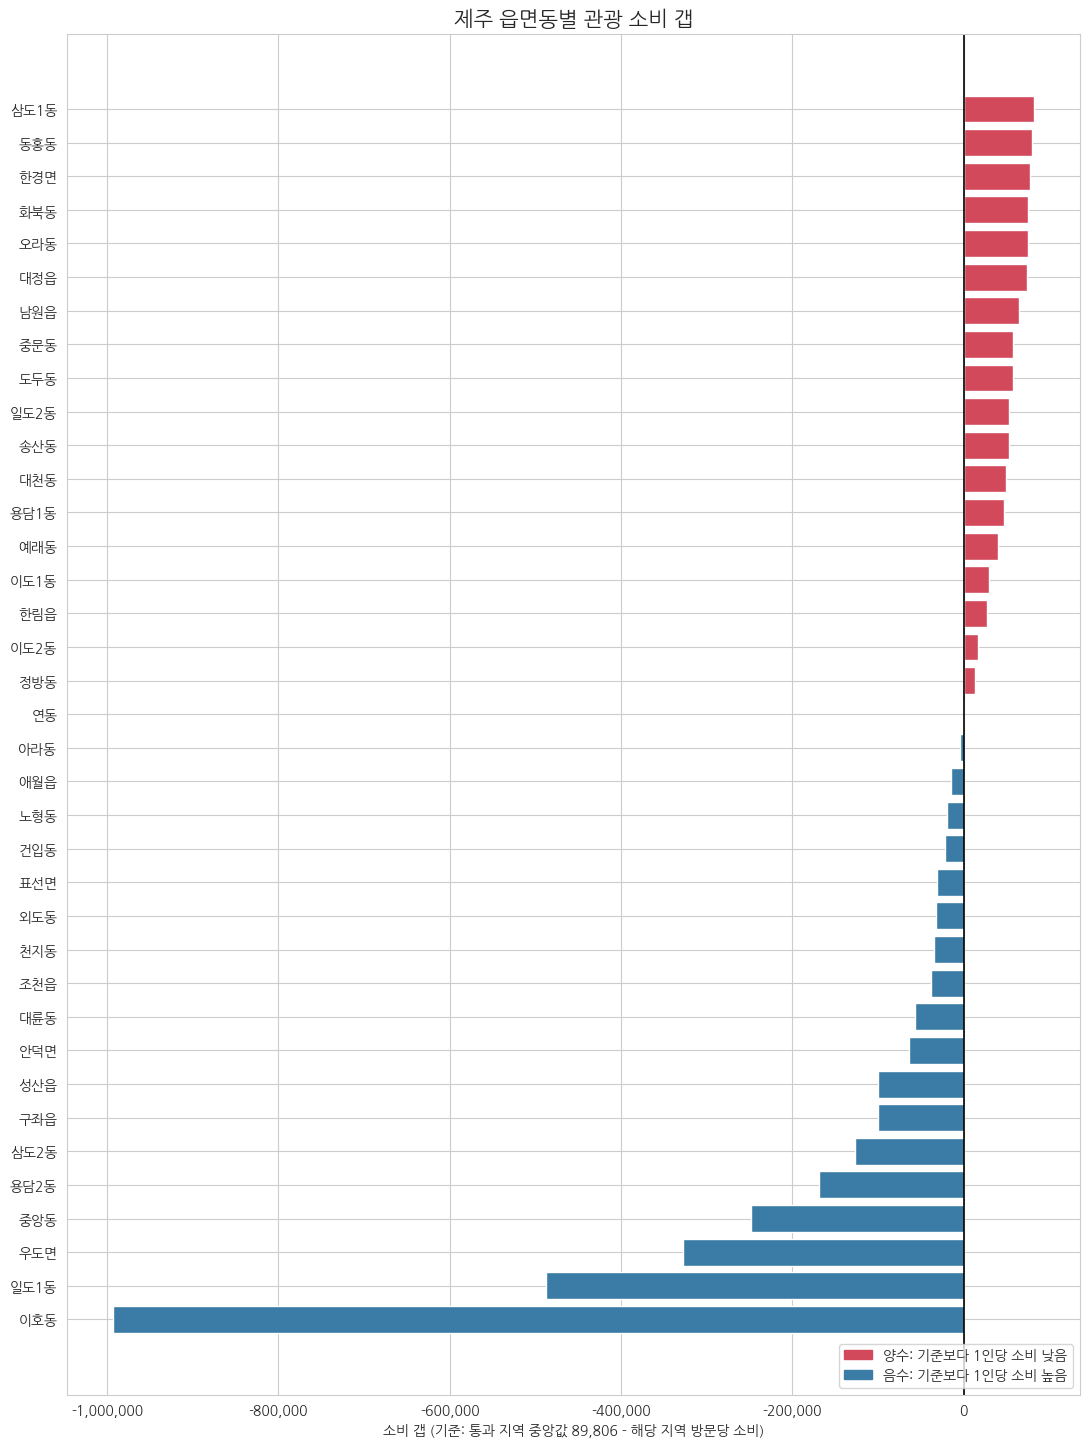

In [ ]:
# ============================================
# 셀 11. 소비 갭 시각화 (그래프 4)
# ============================================
g = agg[agg['수요필터_통과'] == 1].sort_values('소비갭', ascending=False).reset_index(drop=True)
fig, ax = plt.subplots(figsize=(11, 0.34*len(g) + 2))
ax.barh(g[REGION], g['소비갭'], color=np.where(g['소비갭'] > 0, '#D1495B', '#3A7CA5'))
ax.invert_yaxis(); ax.axvline(0, color='black', lw=1.2)
ax.xaxis.set_major_formatter(comma)
ax.set_xlabel(f'소비 갭 (기준: 통과 지역 {REF_RULE} {REF:,.0f} - 해당 지역 방문당 소비)')
ax.set_title('제주 읍면동별 관광 소비 갭', fontsize=15, fontweight='bold')
ax.legend(handles=[Patch(color='#D1495B', label='양수: 기준보다 1인당 소비 낮음'),
                   Patch(color='#3A7CA5', label='음수: 기준보다 1인당 소비 높음')], loc='lower right')
plt.tight_layout(); plt.show()

pos = g[g['소비갭'] > 0]
top3 = ', '.join(f'{r[REGION]}({r["소비갭"]:,.0f})' for _, r in pos.head(3).iterrows())
print(f'해석: 수요 필터 통과 {len(g)}개 지역 중 {len(pos)}개가 소비 갭이 양수입니다. '
      f'갭이 큰 상위 지역은 {top3}입니다. (소비 갭은 상대적 차이일 뿐 결제 인프라 부족을 뜻하지는 않습니다.)')

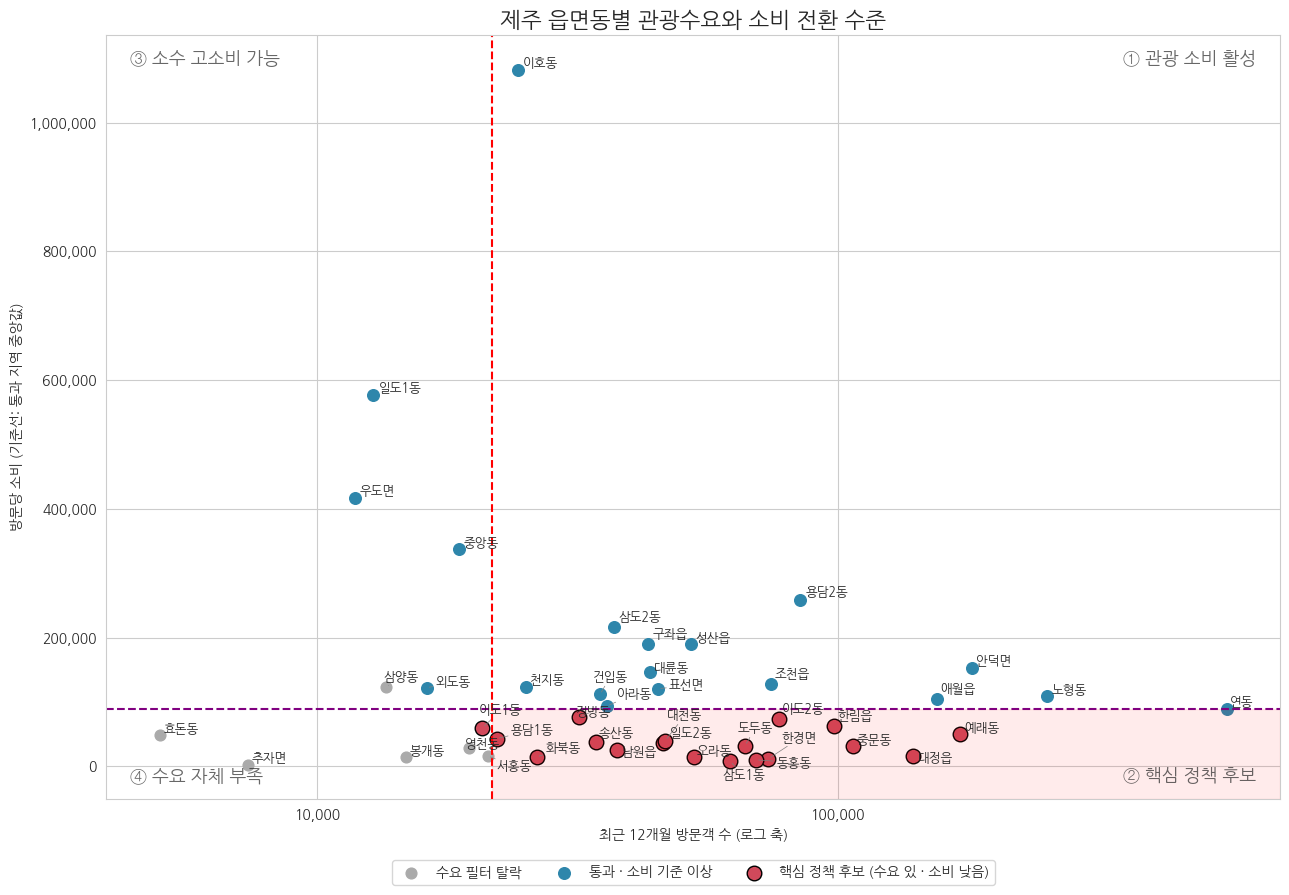

In [ ]:
# ============================================
# 셀 12. 방문객 수 × 방문당 소비 2×2 Scatter Plot (그래프 6)
# ============================================
def classify(r):
    vis = '수요 있음' if r['수요필터_통과'] == 1 else '수요 없음'   # 결제로 통과한 동이 있어 '방문 높음' → '수요 있음'
    con = '소비 높음' if r[SPV] >= REF else '소비 낮음'
    return f'{vis} · {con}'
agg['최종분류'] = agg.apply(classify, axis=1)
agg['정책후보'] = ((agg['수요필터_통과'] == 1) & (agg['소비갭'] > 0)).astype(int)
display(agg['최종분류'].value_counts().to_frame('읍면동 수'))

LOG_X = True
fig, ax = plt.subplots(figsize=(13, 9))
ok_ = agg['수요필터_통과'] == 1
ax.scatter(agg.loc[~ok_, V], agg.loc[~ok_, SPV], c='#AAAAAA', s=60, label='수요 필터 탈락')
ax.scatter(agg.loc[ok_ & (agg['정책후보'] == 0), V], agg.loc[ok_ & (agg['정책후보'] == 0), SPV],
           c='#2E86AB', s=70, label='통과 · 소비 기준 이상')
ax.scatter(agg.loc[agg['정책후보'] == 1, V], agg.loc[agg['정책후보'] == 1, SPV],
           c='#D1495B', s=110, edgecolor='black', label='핵심 정책 후보 (수요 있 · 소비 낮음)')
if LOG_X: ax.set_xscale('log')
ax.xaxis.set_major_formatter(comma); ax.yaxis.set_major_formatter(comma)
ax.axvline(THR, color='red', ls='--', lw=1.5)
ax.axhline(REF, color='purple', ls='--', lw=1.5)
xl, yl = ax.get_xlim(), ax.get_ylim()
ax.add_patch(Rectangle((THR, yl[0]), xl[1] - THR, REF - yl[0], color='red', alpha=0.08))
ax.set_xlim(xl); ax.set_ylim(yl)
for (x, y, t, ha, va) in [(.98, .98, '① 관광 소비 활성', 'right', 'top'),
                          (.98, .02, '② 핵심 정책 후보', 'right', 'bottom'),
                          (.02, .98, '③ 소수 고소비 가능', 'left', 'top'),
                          (.02, .02, '④ 수요 자체 부족', 'left', 'bottom')]:
    ax.text(x, y, t, transform=ax.transAxes, ha=ha, va=va, fontsize=13, fontweight='bold', alpha=.7)
texts = [ax.text(r[V], r[SPV], r[REGION], fontsize=9,
                 fontweight='bold' if r['정책후보'] == 1 else 'normal') for _, r in agg.iterrows()]
adjust_text(texts, ax=ax, arrowprops=dict(arrowstyle='-', color='gray', lw=0.5))
ax.set_xlabel('최근 12개월 방문객 수' + (' (로그 축)' if LOG_X else ''))
ax.set_ylabel(f'방문당 소비 (기준선: 통과 지역 {REF_RULE})')
ax.set_title('제주 읍면동별 관광수요와 소비 전환 수준', fontsize=16, fontweight='bold')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.07), ncol=3)
plt.tight_layout(); plt.show()

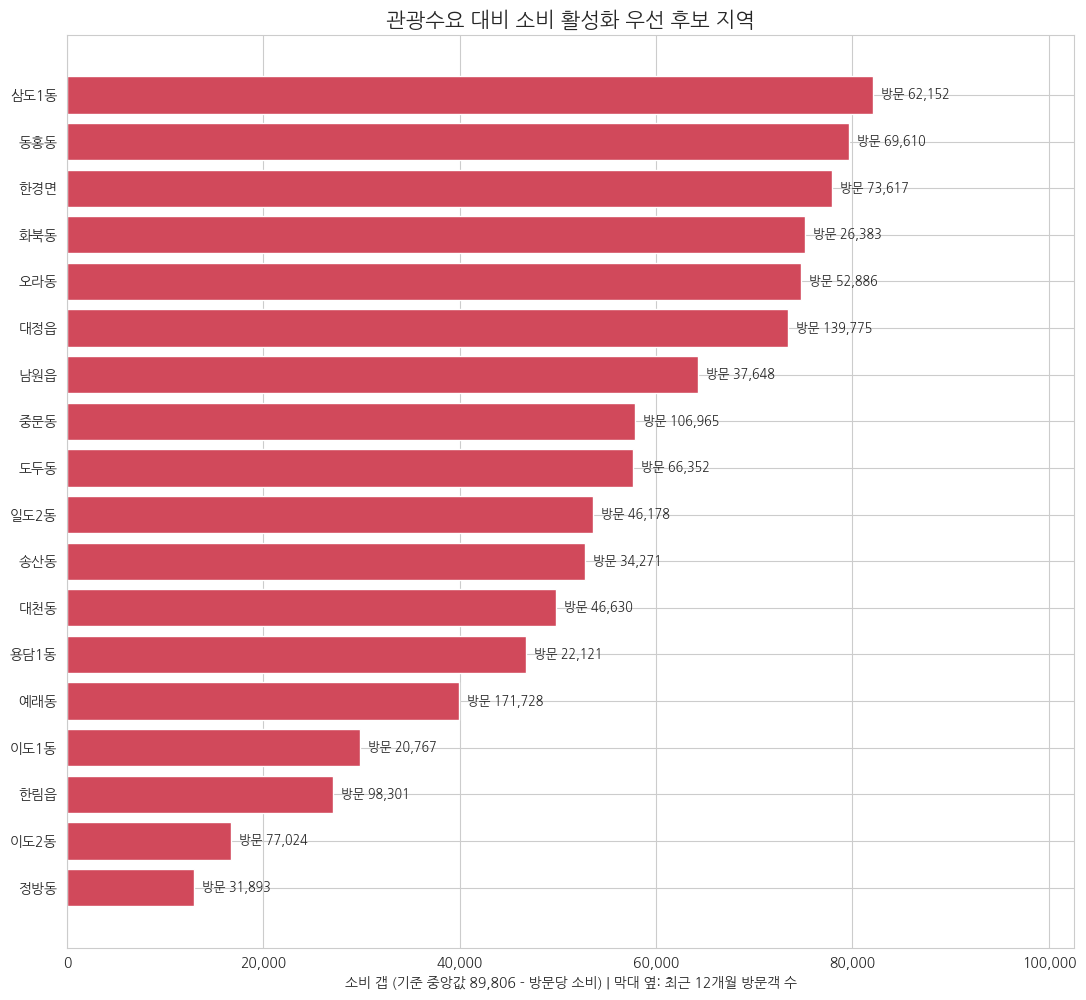

In [ ]:
# ============================================
# 셀 13. 최종 후보 지역 추출 및 시각화 (그래프 5)
# ============================================
cand = agg[agg['정책후보'] == 1].sort_values('소비갭', ascending=False).reset_index(drop=True)
print(f'최종 후보 지역 수: {len(cand)}개 (수요필터 통과 & 소비갭 > 0)')
display(cand[[REGION, V, S, SPV, '소비갭', '소비갭_순위']].rename(columns={REGION: '읍면동'}))

if len(cand):
    fig, ax = plt.subplots(figsize=(11, 0.45*len(cand) + 2))
    ax.barh(cand[REGION], cand['소비갭'], color='#D1495B')
    ax.invert_yaxis()
    xmax = cand['소비갭'].max()
    for i, r in cand.iterrows():
        ax.text(r['소비갭'] + xmax*0.01, i, f'방문 {r[V]:,.0f}', va='center', fontsize=9)
    ax.set_xlim(0, xmax * 1.25)
    ax.xaxis.set_major_formatter(comma)
    ax.set_xlabel(f'소비 갭 (기준 {REF_RULE} {REF:,.0f} - 방문당 소비) | 막대 옆: 최근 12개월 방문객 수')
    ax.set_title('관광수요 대비 소비 활성화 우선 후보 지역', fontsize=15, fontweight='bold')
    plt.tight_layout(); plt.show()
else:
    print('조건을 만족하는 후보가 없습니다.')

In [ ]:
# ============================================
# 셀 14. 최종 결과표 출력
# ============================================
print('1) 실제 분석 기간:', PERIOD_LABEL or 'A 파일에 연월 컬럼 없음 → 파일 전체(이미 집계된 기간)를 사용, 실제 기간은 B(동월) 등으로 별도 확인 필요')
print('2) 전체 읍면동 수:', len(agg))
print(f'3) 수요 필터 기준: {SEL_RULE} (방문객 > {THR:,.0f})')
print('4) 수요 필터 통과 지역 수:', int(agg['수요필터_통과'].sum()))
print('5) 수요 필터 탈락 지역 수:', int((agg['수요필터_통과'] == 0).sum()))
print(f'6) 방문당 소비 기준값: 통과 지역 {REF_RULE} = {REF:,.0f}  (소비금액 컬럼: {SPEND_COL})')
print('7) 소비 갭 산식: 소비갭 = 기준 방문당 소비 - 해당 읍면동 방문당 소비')
print('8) 방문은 충분하지만 소비가 낮은 후보 지역:', ', '.join(cand[REGION]) if len(cand) else '없음')
print('9) 후보 지역별 데이터 근거 (주원인 포함)')
for _, r in cand.iterrows():
    print(f'   - {r[REGION]}: 방문 {r[V]:,.0f}명(전체의 {r["방문객비중(%)"]:.2f}%), 방문당소비 {r[SPV]:,.0f}, '
          f'소비갭 {r["소비갭"]:,.0f} (순위 {int(r["소비갭_순위"])}위) · 주원인 {r["주원인"]}')

final = agg.sort_values(['수요필터_통과', '소비갭'], ascending=[False, False])[
    [REGION, V, S, SPV, '전환', '객단가', '소비갭', '주원인', '수요필터_통과', '소비갭_순위', '최종분류']
].rename(columns={REGION: '읍면동'}).reset_index(drop=True)
print('\n[최종 결과표]')
display(final)

# ---- 공모전 발표용 해석 (실제 계산값 기반) ----
top = cand.head(3)[REGION].tolist()
print('\n[발표용 해석]')
print(f'최근 관광객 방문 데이터에서 읍면동별 방문 규모를 집계하고, 방문이 지나치게 적은 {int((agg["수요필터_통과"]==0).sum())}개 지역은 '
      f'수요 필터({SEL_RULE})로 제외해 {int(agg["수요필터_통과"].sum())}개 지역을 분석 대상으로 삼았습니다. '
      f'이 지역들의 방문당 소비 {REF_RULE}({REF:,.0f})을 기준으로 소비 갭을 계산한 결과, '
      f'{len(cand)}개 지역이 "방문은 충분하지만 1인당 소비는 상대적으로 낮은" 후보로 확인되었고, '
      f'그중 소비 갭이 큰 상위 지역은 {", ".join(top)}입니다. '
      f'다만 이는 관광수요 대비 소비 수준이 상대적으로 낮은 지역을 식별한 것이며, '
      f'결제 인프라와의 관련성은 향후 QR 가맹률·실사용률 데이터를 결합해 검증할 예정입니다.')